# Topology optimization with Helmholtz filtering and projection {far}`star`{far}`star`

```{admonition} Objectives
:class: objectives

This tour solves the classical compliance minimization problem of topology optimization with the SIMP method. The density field is regularized with a Helmholtz-type PDE filter and then projected with a smoothed Heaviside function to obtain a black-and-white design. We show how to compute the sensitivities through the filter and the projection and how to update the design with an optimality criteria method.
$\newcommand{\bu}{\boldsymbol{u}}
\newcommand{\bv}{\boldsymbol{v}}
\newcommand{\bt}{\boldsymbol{t}}
\newcommand{\beps}{\boldsymbol{\varepsilon}}
\newcommand{\CC}{\mathbb{C}}
\newcommand{\dOm}{\,\text{d}\Omega}
\newcommand{\dS}{\,\text{d}S}$
```

```{image} topology_optimization.gif
:width: 700px
:align: center
```

```{admonition} Download sources
:class: download

* {Download}`Python script<./topology_optimization.py>`
* {Download}`Jupyter notebook<./topology_optimization.ipynb>`
```

```{seealso}
This tour revisits the legacy FEniCS tour on [topology optimization using the SIMP method](https://comet-fenics.readthedocs.io/en/latest/demo/topology_optimization/simp_topology_optimization.html), which considers the same problem without filtering or projection.
```

## Problem position

### Compliance minimization

We look for the stiffest structure which can be built inside a design domain $\Omega$ with a prescribed volume of material $V_\text{max}=f_V|\Omega|$, where $f_V$ is the target volume fraction. The structure is clamped on a part of its boundary and loaded by surface tractions $\bt$ on another part $\Gamma_\text{N}$. Its stiffness is measured by the *compliance*, i.e. the work of external forces $C = \int_{\Gamma_\text{N}} \bt\cdot\bu \dS$, which we seek to minimize.

Following the SIMP (Solid Isotropic Material with Penalization) approach {cite:p}`bendsoe2004topology`, the material distribution is described by a density field $\overline{\rho}(\boldsymbol{x})\in[0;1]$ and the Young modulus is interpolated as:

```{math}
:label: simp

E(\overline{\rho}) = E_\text{min} + \overline{\rho}^p(E_0-E_\text{min})
```

where $E_0$ is the Young modulus of the solid phase and $E_\text{min} \ll E_0$ is a small residual stiffness which prevents the stiffness matrix from becoming singular in void regions. The penalization exponent $p>1$ (typically $p=3$) makes intermediate densities uneconomical, as they provide little stiffness for their cost in volume. The optimization problem reads:

```{math}
:label: compliance-pb

\begin{array}{rl}
\displaystyle\min_{\rho} & C(\rho) = \displaystyle\int_{\Gamma_\text{N}} \bt\cdot\bu \dS\\
\text{s.t.} & \displaystyle\int_\Omega E(\overline{\rho})\,\CC_1:\beps(\bu):\beps(\bv)\dOm = \int_{\Gamma_\text{N}} \bt\cdot\bv \dS \quad \forall \bv\\
& V(\rho) = \displaystyle\int_\Omega \overline{\rho}\dOm \leq f_V|\Omega| \\
& 0 \leq \rho \leq 1
\end{array}
```

where $\CC_1$ is the isotropic elasticity tensor with unit Young modulus and Poisson ratio $\nu$.

### Regularization by filtering and projection

The design variable $\rho$ is piecewise constant on the mesh. Without regularization, the problem is ill-posed: the solution depends on the mesh, finer meshes producing ever finer structural members, and checkerboard patterns of alternating solid and void elements appear. A classical remedy is to *filter* the design variable, which imposes a minimum length scale on the design. Here, we use the PDE filter of {cite:p}`lazarov2011filters`, in which the filtered density $\widetilde{\rho}$ is the solution of a Helmholtz-type equation:

```{math}
:label: helmholtz

-r^2\Delta \widetilde{\rho} + \widetilde{\rho} = \rho \quad \text{in } \Omega, \qquad \nabla\widetilde{\rho}\cdot\boldsymbol{n} = 0 \quad \text{on } \partial\Omega
```

The length parameter $r$ is related to the radius $R$ of the classical convolution-based density filter by $r = R/(2\sqrt{3})$. This filter only requires solving a linear PDE with the same mesh and finite element tools as the mechanical problem, which makes it very convenient in a finite element framework.

Filtering smears the interfaces between solid and void over a distance of order $R$, so that filtered designs contain gray regions. To recover a black-and-white design, the filtered density is *projected* with a smoothed Heaviside function {cite:p}`wang2011projection`:

```{math}
:label: projection

\overline{\rho} = H_\beta(\widetilde{\rho}) = \dfrac{\tanh(\beta\eta) + \tanh(\beta(\widetilde{\rho}-\eta))}{\tanh(\beta\eta) + \tanh(\beta(1-\eta))}
```

where $\eta$ is a threshold, here $\eta = 1/2$, and $\beta$ controls the sharpness of the projection. For $\beta\to 0$, $H_\beta$ tends to the identity, while it tends to a step function for $\beta\to\infty$. Since a sharp projection makes the optimization problem highly nonlinear, $\beta$ is progressively increased during the optimization (*continuation*). The projected density $\overline{\rho}$, used in {eq}`simp` and in the volume constraint, is called the *physical* density.

We therefore work with three density fields:
* the design variable $\rho$, discretized with piecewise constant (`"DG"` of degree 0) functions;
* the filtered density $\widetilde{\rho}$, discretized with continuous piecewise linear functions;
* the physical density $\overline{\rho} = H_\beta(\widetilde{\rho})$, which is never stored but directly used as a UFL expression in the forms.

### Sensitivity analysis

Gradient-based optimization requires the derivatives of the compliance and of the volume with respect to the design variables. Since the loading does not depend on the design, the compliance problem is self-adjoint and the derivative of the compliance with respect to the physical density is given by:

```{math}
:label: compliance-sensitivity

\dfrac{\partial C}{\partial\overline{\rho}}\cdot\delta\overline{\rho} = -\int_\Omega E'(\overline{\rho})\,\delta\overline{\rho}\;\CC_1:\beps(\bu):\beps(\bu)\dOm
```

With $\delta\overline{\rho} = H'_\beta(\widetilde{\rho})\,\delta\widetilde{\rho}$, the derivative with respect to the filtered density is a linear form in $\delta\widetilde{\rho}$ which is obtained automatically with `ufl.derivative`.

The last step goes through the filter. After discretization, the weak form of {eq}`helmholtz` reads $[\mathbf{A}]\{\widetilde{\rho}\} = [\mathbf{B}]\{\rho\}$, where $[\mathbf{A}]$ is the matrix associated with the bilinear form $\int_\Omega (r^2\nabla\widetilde{\rho}\cdot\nabla q + \widetilde{\rho} q)\dOm$ and $[\mathbf{B}]$ is the mixed mass matrix associated with $\int_\Omega \rho\, q\dOm$. For any function $J$, the chain rule then gives:

```{math}
:label: filter-sensitivity

\left\{\dfrac{\partial J}{\partial \rho}\right\} = [\mathbf{B}]^\text{T}[\mathbf{A}]^{-1}\left\{\dfrac{\partial J}{\partial \widetilde{\rho}}\right\}
```

since $[\mathbf{A}]$ is symmetric. In practice, we solve the filter problem with $\{\partial J/\partial \widetilde{\rho}\}$ as a right-hand side, which gives a field $\lambda$, and the product with $[\mathbf{B}]^\text{T}$ amounts to integrating $\lambda$ over each cell: $\partial J/\partial \rho_e = \int_{\Omega_e}\lambda\dOm$.

### Optimality criteria update

The design is updated with the optimality criteria (OC) method {cite:p}`bendsoe2004topology,andreassen2011efficient`. In each cell $e$, the new density is given by:

```{math}
:label: oc-update

\rho_e^\text{new} = \min\left\{\min(1, \rho_e + m),\; \max\left\{\max(0, \rho_e - m),\; \rho_e\left(-\dfrac{\partial C/\partial \rho_e}{\ell\, \partial V/\partial \rho_e}\right)^{1/2}\right\}\right\}
```

where $m$ is a move limit and $\ell$ is a Lagrange multiplier, found by bisection such that the new physical design satisfies the volume constraint. Since the physical density depends on the design variables through the filter, each bisection step requires a filter solve. This is inexpensive since the filter matrix is factorized once and for all.

```{note}
In the legacy version of this tour, the densities were updated with a closed-form formula derived from an alternate minimization algorithm {cite:p}`allaire2007conception`. This update relies on the fact that the problem is local in the density variable, which is no longer the case once the density is filtered. We therefore use the sensitivity-based OC update instead.
```

## Implementation

We first import the relevant modules and define the problem parameters. We consider the same cantilever beam as in the legacy tour, of length $L=4$ and height $H=1$. The beam is clamped on its left end and loaded by a uniform downward traction on a segment of length $0.1$ at the middle of its right end. The target volume fraction is $f_V=0.4$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from mpi4py import MPI
from petsc4py import PETSc
import ufl
from dolfinx import fem, mesh
import dolfinx.fem.petsc
from dolfinx.fem.petsc import LinearProblem

comm = MPI.COMM_WORLD

L, H = 4.0, 1.0  # beam dimensions
Nx, Ny = 200, 50  # number of elements
vol_frac = 0.4  # target volume fraction

E0, Emin, nu = 1.0, 1e-9, 0.3  # material properties
penal = 3.0  # SIMP penalization exponent
r_filter = 0.04  # Helmholtz filter length (R = 2*sqrt(3)*r ~ 7 elements)
eta = 0.5  # projection threshold

We use a structured mesh of quadrilaterals so that each element corresponds to one design variable. The displacement is discretized with quadratic Lagrange elements.

In [2]:
domain = mesh.create_rectangle(
    comm, [(-L / 2, 0.0), (L / 2, H)], [Nx, Ny], cell_type=mesh.CellType.quadrilateral
)
gdim = domain.geometry.dim
tdim = domain.topology.dim

V = fem.functionspace(domain, ("Lagrange", 2, (gdim,)))  # displacement
W = fem.functionspace(domain, ("DG", 0))  # design variable
V_rho = fem.functionspace(domain, ("Lagrange", 1))  # filtered density

rho = fem.Function(W, name="Design")
rho_tilde = fem.Function(V_rho, name="Filtered_density")

The projection parameter $\beta$ is defined as a `fem.Constant` so that it can be updated during the continuation without recompiling the forms. The physical density {eq}`projection` and the SIMP interpolation {eq}`simp` are pure UFL expressions of the filtered density.

In [3]:
beta = fem.Constant(domain, 1.0)


def projection(x):
    return (ufl.tanh(beta * eta) + ufl.tanh(beta * (x - eta))) / (
        ufl.tanh(beta * eta) + ufl.tanh(beta * (1 - eta))
    )


rho_bar = projection(rho_tilde)
E = Emin + rho_bar**penal * (E0 - Emin)


def epsilon(v):
    return ufl.sym(ufl.grad(v))


def sigma(v, E):
    lmbda = E * nu / (1 + nu) / (1 - 2 * nu)
    mu = E / 2 / (1 + nu)
    return lmbda * ufl.tr(epsilon(v)) * ufl.Identity(gdim) + 2 * mu * epsilon(v)

We define the boundary conditions and the loading. Since the forms involve the non-polynomial projection function, we fix the quadrature degree. It is important to use the same quadrature rule in the stiffness matrix and in the sensitivity forms so that the computed sensitivities are the exact derivatives of the discrete compliance.

In [4]:
left_facets = mesh.locate_entities_boundary(
    domain, tdim - 1, lambda x: np.isclose(x[0], -L / 2)
)
left_dofs = fem.locate_dofs_topological(V, tdim - 1, left_facets)
bcs = [fem.dirichletbc(np.zeros(gdim), left_dofs, V)]

load_facets = mesh.locate_entities_boundary(
    domain,
    tdim - 1,
    lambda x: np.isclose(x[0], L / 2) & (np.abs(x[1] - H / 2) <= 0.05 + 1e-8),
)
facet_tags = mesh.meshtags(
    domain, tdim - 1, np.sort(load_facets), np.ones_like(load_facets)
)
ds = ufl.Measure("ds", domain=domain, subdomain_data=facet_tags)
dx = ufl.Measure("dx", domain=domain, metadata={"quadrature_degree": 4})

t = fem.Constant(domain, (0.0, -1.0))

The elasticity problem is defined once and for all, since the stiffness matrix is automatically reassembled with the current density at each call to `solve`.

In [5]:
u = fem.Function(V, name="Displacement")
du = ufl.TrialFunction(V)
v = ufl.TestFunction(V)
a = ufl.inner(sigma(du, E), epsilon(v)) * dx
ell = ufl.dot(t, v) * ds(1)

elasticity_problem = LinearProblem(
    a,
    ell,
    u=u,
    bcs=bcs,
    petsc_options={
        "ksp_type": "preonly",
        "pc_type": "lu",
        "pc_factor_mat_solver_type": "mumps",
    },
    petsc_options_prefix="elasticity_",
)

We now define the compliance and the volume fraction, as well as their derivatives {eq}`compliance-sensitivity` with respect to the filtered density. The latter are obtained with `ufl.derivative` which differentiates through the projection function. We also define a measure of non-discreteness $M_\text{nd} = \frac{4}{|\Omega|}\int_\Omega \overline{\rho}(1-\overline{\rho})\dOm$, which vanishes for a black-and-white design and is equal to $1$ for a uniform gray design $\overline{\rho}=1/2$ {cite:p}`wang2011projection`.

In [6]:
area = L * H
q = ufl.TestFunction(V_rho)

compliance = fem.form(ufl.dot(t, u) * ds(1))
dcompliance = fem.form(
    -ufl.derivative(ufl.inner(sigma(u, E), epsilon(u)) * dx, rho_tilde, q)
)
volume = fem.form(rho_bar / area * dx)
dvolume = fem.form(ufl.derivative(rho_bar / area * dx, rho_tilde, q))
non_discreteness = fem.form(4 * rho_bar * (1 - rho_bar) / area * dx)


def assemble_scalar(form):
    return comm.allreduce(fem.assemble_scalar(form), op=MPI.SUM)

### Helmholtz filter

The `HelmholtzFilter` class implements the weak form of {eq}`helmholtz` and the corresponding sensitivity filtering {eq}`filter-sensitivity`. The filter matrix $[\mathbf{A}]$ does not depend on the design. It is assembled and factorized only once, so that each filter application only requires a forward and backward substitution. No boundary condition is needed since the homogeneous Neumann condition is natural.

In [7]:
class HelmholtzFilter:
    """Helmholtz PDE filter mapping a DG-0 design rho onto a P1 filtered density."""

    def __init__(self, rho, rho_tilde, r):
        self.rho_tilde = rho_tilde
        V_rho = rho_tilde.function_space
        p_, q_ = ufl.TrialFunction(V_rho), ufl.TestFunction(V_rho)
        A_form = fem.form(
            r**2 * ufl.dot(ufl.grad(p_), ufl.grad(q_)) * ufl.dx + p_ * q_ * ufl.dx
        )
        self.A = fem.petsc.assemble_matrix(A_form)
        self.A.assemble()
        self.solver = PETSc.KSP().create(comm)
        self.solver.setOperators(self.A)
        self.solver.setType("preonly")
        self.solver.getPC().setType("lu")
        self.solver.getPC().setFactorSolverType("mumps")

        self.L = fem.form(rho * q_ * ufl.dx)
        self.b = fem.petsc.create_vector(V_rho)

        # form computing the product with B^T, i.e. integrating lambda over each cell
        self.lmbda = fem.Function(V_rho)
        w_ = ufl.TestFunction(rho.function_space)
        self.BT_lambda = fem.form(self.lmbda * w_ * ufl.dx)

    def apply(self):
        """Compute the filtered density from the current design."""
        with self.b.localForm() as b_local:
            b_local.set(0.0)
        fem.petsc.assemble_vector(self.b, self.L)
        self.b.ghostUpdate(addv=PETSc.InsertMode.ADD, mode=PETSc.ScatterMode.REVERSE)
        self.solver.solve(self.b, self.rho_tilde.x.petsc_vec)
        self.rho_tilde.x.scatter_forward()

    def sensitivity(self, dJ_form):
        """Compute dJ/drho from the linear form dJ/drho_tilde."""
        g = fem.petsc.assemble_vector(dJ_form)
        g.ghostUpdate(addv=PETSc.InsertMode.ADD, mode=PETSc.ScatterMode.REVERSE)
        self.solver.solve(g, self.lmbda.x.petsc_vec)
        self.lmbda.x.scatter_forward()
        g.destroy()
        return fem.assemble_vector(self.BT_lambda).array


helmholtz_filter = HelmholtzFilter(rho, rho_tilde, r_filter)

### Optimality criteria update

The OC update {eq}`oc-update` is performed on the locally owned design variables. The Lagrange multiplier is found by bisection, each step filtering the candidate design and evaluating its volume. The function returns the maximum change of the design variables.

In [8]:
num_cells = W.dofmap.index_map.size_local


def oc_update(dC, dV, move):
    rho_old = rho.x.array[:num_cells].copy()
    B = np.sqrt(np.maximum(-dC[:num_cells], 0.0) / np.maximum(dV[:num_cells], 1e-30))
    lower = np.maximum(0.0, rho_old - move)
    upper = np.minimum(1.0, rho_old + move)
    l1, l2 = 0.0, 1e9
    for _ in range(100):  # bisection on the Lagrange multiplier
        lmid = 0.5 * (l1 + l2)
        rho.x.array[:num_cells] = np.clip(rho_old * B / np.sqrt(lmid), lower, upper)
        rho.x.scatter_forward()
        helmholtz_filter.apply()
        if assemble_scalar(volume) > vol_frac:
            l1 = lmid
        else:
            l2 = lmid
        if l2 - l1 < 1e-4 * (l1 + l2):
            break
    change = np.max(np.abs(rho.x.array[:num_cells] - rho_old), initial=0.0)
    return comm.allreduce(change, op=MPI.MAX)

### Optimization loop

We start from a uniform design satisfying the volume constraint. The projection parameter $\beta$ is doubled from $1$ to $32$ every $40$ iterations, or earlier if the design change becomes small. As $\beta$ increases, a small change of the design variables produces a large change of the physical density. We therefore reduce the move limit for large values of $\beta$ to avoid oscillations of the design. At the end of each continuation step, the physical density is interpolated on the `"DG"` space for visualization.

In [9]:
betas = [1, 2, 4, 8, 16, 32]
num_iter_per_beta = 40
tol = 0.01

rho_bar_cells = fem.Function(W, name="Physical_density")
rho_bar_expr = fem.Expression(rho_bar, W.element.interpolation_points)
snapshots = []
history = []
rho.x.array[:] = vol_frac
helmholtz_filter.apply()
for beta_value in betas:
    beta.value = beta_value
    move = 0.2 if beta_value < 8 else 0.05
    for i in range(num_iter_per_beta):
        elasticity_problem.solve()
        C = assemble_scalar(compliance)
        dC = helmholtz_filter.sensitivity(dcompliance)
        dV = helmholtz_filter.sensitivity(dvolume)
        change = oc_update(dC, dV, move)
        history.append([beta_value, C, assemble_scalar(non_discreteness), change])
        if change < tol:
            break
    rho_bar_cells.interpolate(rho_bar_expr)
    snapshots.append(rho_bar_cells.x.array.copy())
    if comm.rank == 0:
        print(
            f"beta = {beta_value:2d}: {len(history):3d} iterations, compliance {C:.4f}, "
            f"non-discreteness {history[-1][2]:.1%}"
        )
history = np.array(history)

beta =  1:  40 iterations, compliance 3.9438, non-discreteness 48.3%
beta =  2:  80 iterations, compliance 3.6291, non-discreteness 42.1%
beta =  4: 120 iterations, compliance 3.1415, non-discreteness 30.2%
beta =  8: 160 iterations, compliance 2.7356, non-discreteness 15.9%
beta = 16: 200 iterations, compliance 2.5611, non-discreteness 7.7%
beta = 32: 240 iterations, compliance 2.4901, non-discreteness 3.9%


## Results

We plot the physical density obtained at the end of each continuation step. The filtered design obtained with $\beta=1$ contains large gray regions. As $\beta$ increases, the projection progressively sharpens the interfaces and the final design is almost black and white. Note also that the compliance decreases along the continuation since the stiffness of intermediate densities is penalized by the SIMP interpolation.

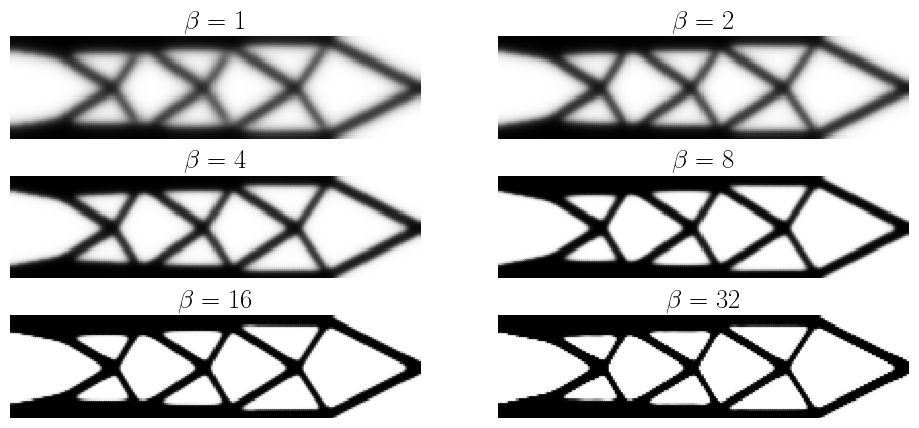

In [10]:
# quadrilateral vertices in counter-clockwise order for plotting
cells = domain.geometry.dofmaps[0][:num_cells][:, [0, 1, 3, 2]]
polygons = domain.geometry.x[cells, :2]
cell_dofs = W.dofmap.list[:num_cells, 0]

fig, axes = plt.subplots(3, 2, figsize=(10, 4.5))
for ax, beta_value, values in zip(axes.flat, betas, snapshots):
    collection = PolyCollection(
        polygons, array=values[cell_dofs], cmap="gray_r", clim=(0, 1), edgecolors="face"
    )
    ax.add_collection(collection)
    ax.set_xlim(-L / 2, L / 2)
    ax.set_ylim(0, H)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(rf"$\beta = {beta_value}$")
plt.tight_layout()
plt.show()

Finally, we plot the evolution of the compliance and of the measure of non-discreteness during the iterations. The vertical lines indicate the iterations at which $\beta$ is doubled. Each increase of $\beta$ produces a jump of both quantities, followed by a convergence towards a new, crisper design.

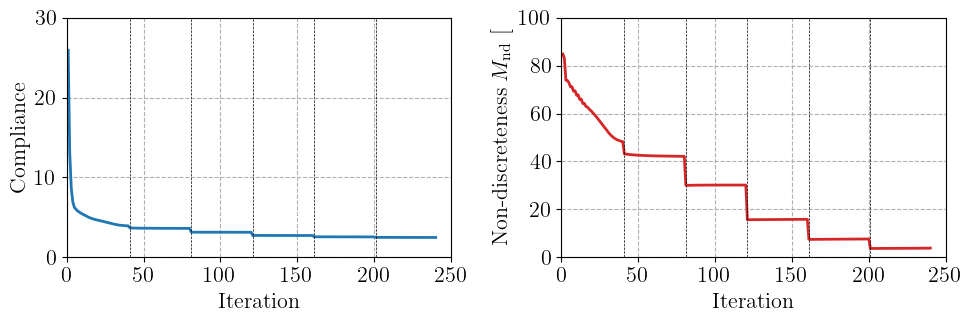

In [11]:
iterations = np.arange(1, len(history) + 1)
beta_changes = iterations[np.flatnonzero(np.diff(history[:, 0])) + 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(iterations, history[:, 1], "-C0")
ax1.set_ylabel("Compliance")
ax2.plot(iterations, 100 * history[:, 2], "-C3")
ax2.set_ylabel(r"Non-discreteness $M_\text{nd}$ [%]")
ax2.set_ylim(0, 100)
for ax in (ax1, ax2):
    ax.set_xlabel("Iteration")
    for it in beta_changes:
        ax.axvline(it, color="k", lw=0.5, ls="--")
plt.tight_layout()
plt.show()

```{note}
The design obtained with this approach is a local optimum, which depends on the initial design, the filter radius and the continuation strategy. Besides, the minimum length scale imposed by the filter is no longer guaranteed after a sharp projection, since thin members can be obtained by thresholding a smoothly varying filtered field. Robust formulations based on eroded and dilated designs impose a minimum length scale on both the solid and void phases {cite:p}`wang2011projection`.
```

## References

```{bibliography}
:filter: docname in docnames
```